<a href="https://colab.research.google.com/github/Prasanna-datascience/Data110Class/blob/main/Data201_Project1_Prasanna%20Sadashivaiah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Unnamed: 0  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  \
0           1   63    1       typical     145   233    1        2    150   
1           2   67    1  asymptomatic     160   286    0        2    108   
2           3   67    1  asymptomatic     120   229    0        2    129   
3           4   37    1    nonanginal     130   250    0        0    187   
4           5   41    0    nontypical     130   204    0        2    172   

   ExAng  Oldpeak  Slope   Ca        Thal  AHD  
0      0      2.3      3  0.0       fixed   No  
1      1      1.5      2  3.0      normal  Yes  
2      1      2.6      2  2.0  reversable  Yes  
3      0      3.5      3  0.0      normal   No  
4      0      1.4      1  0.0      normal   No  
Accuracy: 0.868
ROC AUC: 0.937

Confusion Matrix
[[35  6]
 [ 4 31]]

True Negatives : 35
False Positives: 6
False Negatives: 4
True Positives : 31

Classification Report
              precision    recall  f1-score   support

           0       0.90 

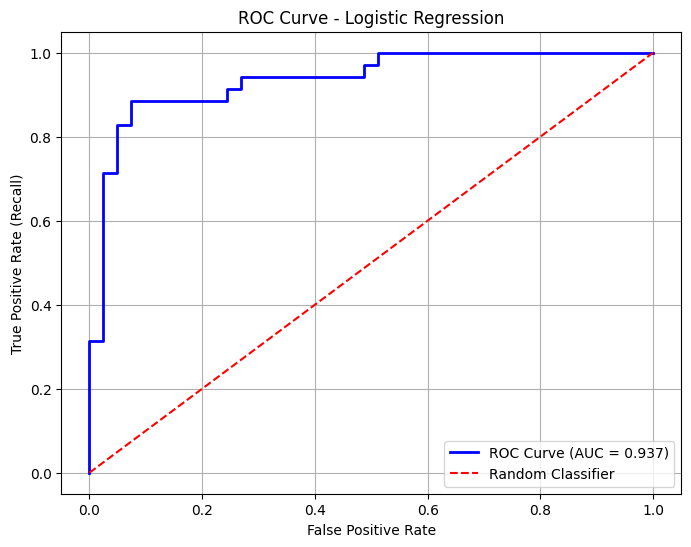

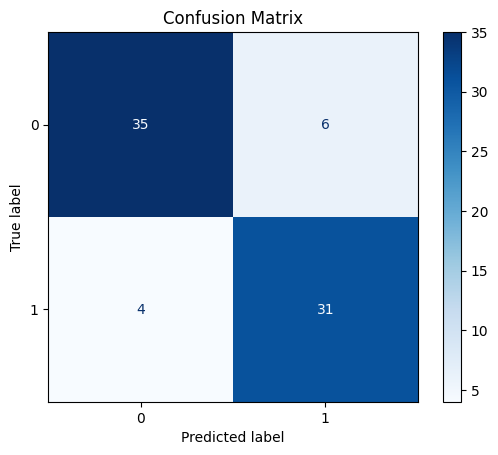

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

# ---------------------------
# Load data
# ---------------------------
url = "https://raw.githubusercontent.com/Reben80/Data201-Fall2026-CRN21732/main/Dataset/Heart.csv"

heart = pd.read_csv(url)

print(heart.head())

# Remove the unnamed index column if present
if "Unnamed: 0" in heart.columns:
    heart = heart.drop(columns="Unnamed: 0")

# Convert target to 0/1
heart["AHD"] = heart["AHD"].map({"No": 0, "Yes": 1})

# Replace text missing values
heart = heart.replace("NA", np.nan)

# ---------------------------
# Features and target
# ---------------------------
X = heart.drop(columns="AHD")
y = heart["AHD"]

# Identify column types
cat_cols = X.select_dtypes(include=["object"]).columns
num_cols = X.select_dtypes(exclude=["object"]).columns

# ---------------------------
# Preprocessing
# ---------------------------
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

# ---------------------------
# Train/Test Split
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# ---------------------------
# Logistic Regression Model
# ---------------------------
model = Pipeline([
    ("prep", preprocessor),
    ("logistic", LogisticRegression(max_iter=500))
])

model.fit(X_train, y_train)

# ---------------------------
# Predictions
# ---------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# ---------------------------
# Evaluation
# ---------------------------
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 3))

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# ---------------------------
# Lower the threshold
# ---------------------------
threshold = 0.30

y_pred_30 = (y_prob >= threshold).astype(int)

cm30 = confusion_matrix(y_test, y_pred_30)

print("\nConfusion Matrix (Threshold = 0.30)")
print(cm30)

tn, fp, fn, tp = cm30.ravel()

print(f"\nFalse Negatives at 0.30: {fn}")
print(f"False Positives at 0.30: {fp}")

print("\nClassification Report (Threshold = 0.30)")
print(classification_report(y_test, y_pred_30))



# Add an ROC Curve Graph
y_prob = model.predict_proba(X_test)[:, 1]
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    color="blue",
    lw=2,
    label=f"ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()


# Adding confusion Matrix Graph
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()









Cross-Validation Results
  Model  Mean Accuracy   Std Dev
0   KNN       0.797391  0.025496
Best K = 5
Best Accuracy = 0.797391304347826


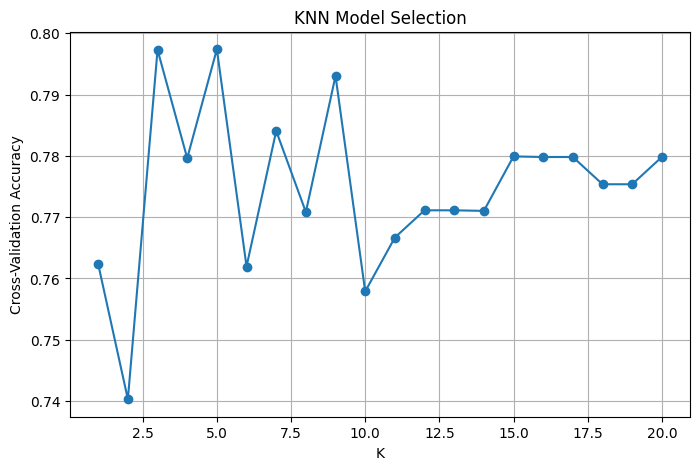

In [10]:
# ----------------------------------
# Import Models
# ----------------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
LinearDiscriminantAnalysis,
QuadraticDiscriminantAnalysis
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
import pandas as pd

# ----------------------------------
# Define Models
# ----------------------------------

models = {
"Logistic Regression": LogisticRegression(max_iter=1000),
"LDA": LinearDiscriminantAnalysis(),
"QDA": QuadraticDiscriminantAnalysis(),
"KNN": KNeighborsClassifier(n_neighbors=5)
}

# ----------------------------------
# Compare Models with Cross Validation
# ----------------------------------

results = []

for name, model in models.items():

  pipeline = Pipeline([
    ("prep", preprocessor),
    ("classifier", model)
])

scores = cross_val_score(
pipeline,
X_train,
y_train,
cv=5,
scoring="accuracy"
)

results.append({
"Model": name,
"Mean Accuracy": scores.mean(),
"Std Dev": scores.std()
})

results_df = pd.DataFrame(results)

print("\nCross-Validation Results")
print(results_df.sort_values(
by="Mean Accuracy",
ascending=False
))
# Evaluate Each Model on the Test Set
# ----------------------------------
# Test Set Evaluation
# ----------------------------------

test_results = []

for name, model in models.items():

  pipeline = Pipeline([
    ("prep", preprocessor),
    ("classifier", model)
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, y_pred)

test_results.append({
"Model": name,
"Test Accuracy": acc
})


# Best K for KNN
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

k_values = range(1, 21)
cv_scores = []

for k in k_values:

    knn_pipeline = Pipeline([
        ("prep", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        knn_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())

best_k = k_values[cv_scores.index(max(cv_scores))]

print("Best K =", best_k)
print("Best Accuracy =", max(cv_scores))

plt.figure(figsize=(8,5))
plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Cross-Validation Accuracy")
plt.title("KNN Model Selection")
plt.grid(True)
plt.show()